In [1]:
import os
import sys

# necessary to make functions available
# Jupyter server should be running from src/python
sys.path.append(
    os.getcwd()
)

In [2]:
import os

import polars as pl

import synapseclient

from feature_distribution_plots import (
    two_group_ridge
)
from colors import COLORS


In [3]:
# Jupyter server should be running from src/python
FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures",
    "lipids"
)

# synapse IDs
META_CACHE_SYNID = "syn74775994"
COMBINED_CACHE_SYNID = "syn74775996"
LIMMA_RESULTS_SYNID = "syn78408378"
GSEA_RESULTS_SYNID = "syn78432275"

In [4]:
os.makedirs(FIGURE_DIR, exist_ok=True)

In [5]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.15.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.15.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



In [6]:
# load sample metadata and combined omics data
meta = pl.read_parquet(SYN.get(META_CACHE_SYNID).path)
combined = pl.read_parquet(SYN.get(COMBINED_CACHE_SYNID).path)

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_17499/3218487284.py:2: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  meta = pl.read_parquet(SYN.get(META_CACHE_SYNID).path)



[syn74775994:metadata.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/metadata.parquet, skipping download.


[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_17499/3218487284.py:3: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  combined = pl.read_parquet(SYN.get(COMBINED_CACHE_SYNID).path)



[syn74775996:combined_omics_data.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/combined_omics_data.parquet, skipping download.


In [7]:
# load limma and gsea results
limma = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)
gsea = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_17499/1942229129.py:2: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  limma = pl.read_parquet(SYN.get(LIMMA_RESULTS_SYNID).path)



[syn78408378:limma_results.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/limma/limma_results.parquet, skipping download.


[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_17499/1942229129.py:3: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  gsea = pl.read_parquet(SYN.get(GSEA_RESULTS_SYNID).path)



[syn78432275:gsea_results.parquet]: Found existing file at /Users/dylan.ross/.synapseCache/383/178910383/gsea_results.parquet, skipping download.


In [8]:
# create a table for selecting out sets of individual features
features = (
    combined.unpivot(
        index=["OmicsType", "Feature"],
        variable_name="Sample",
        value_name="Signal"
    )
    .filter(pl.col("Signal").is_not_null())
    .join(
        meta, on="Sample", how="left"
    )
)

features

OmicsType,Feature,Sample,Signal,Age,Sex,Race,Study,FLT3_ITD,NPM1
str,str,str,f64,f64,str,str,str,bool,bool
"""Acetylomics""","""ACAA2-K234k""","""11-00261""",-2.79,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACAD9-K202k""","""11-00261""",-0.195,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACADM-K304k""","""11-00261""",-0.129,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACADVL-K278k""","""11-00261""",0.272,74.0,"""Male""","""White""","""BeatAML""",true,false
"""Acetylomics""","""ACADVL-K298k""","""11-00261""",-0.622,74.0,"""Male""","""White""","""BeatAML""",true,false
…,…,…,…,…,…,…,…,…,…
"""Phosphoproteomics""","""ZYX-S281s""","""17-00881-Bridge""",-1.342814,76.0,"""Female""","""White""","""pilotStudy""",false,false
"""Phosphoproteomics""","""ZYX-S308s""","""17-00881-Bridge""",-1.989973,76.0,"""Female""","""White""","""pilotStudy""",false,false
"""Phosphoproteomics""","""ZYX-S344s""","""17-00881-Bridge""",-0.039027,76.0,"""Female""","""White""","""pilotStudy""",false,false


## utility

In [33]:
def make_dz_df(features, genes, race):
    return (
        pl.DataFrame([
        (
            g, 
            (
                features
                .filter(
                    (pl.col("Race") == race)
                    & (pl.col("OmicsType") == omics_type)
                    & (pl.col("Feature") == g)
                    & ~pl.col("FLT3_ITD")
                )
                .group_by("Feature")
                .agg(
                    "Signal",
                    "Sample",
                    "NPM1"
                )
                .with_columns(
                    pl.col("Signal").list.mean().alias("Signal_mean"),
                    pl.col("Signal").list.std().alias("Signal_std")
                )
                .with_columns(
                    ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                )
                .drop("Signal", "Signal_mean", "Signal_std")
                .explode("Sample", "NPM1", "Z")
                .filter(~pl.col("NPM1"))
                ["Z"]
                .to_list()
            ),
            (
                features
                .filter(
                    (pl.col("Race") == race)
                    & (pl.col("OmicsType") == omics_type)
                    & (pl.col("Feature") == g)
                    & ~pl.col("FLT3_ITD")
                )
                .group_by("Feature")
                .agg(
                    "Signal",
                    "Sample",
                    "NPM1"
                )
                .with_columns(
                    pl.col("Signal").list.mean().alias("Signal_mean"),
                    pl.col("Signal").list.std().alias("Signal_std")
                )
                .with_columns(
                    ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                )
                .drop("Signal", "Signal_mean", "Signal_std")
                .explode("Sample", "NPM1", "Z")
                .filter(pl.col("NPM1"))
                ["Z"]
                .to_list()
            )
        )
        for g, omics_type
        in genes
    ], schema=["feature", "A", "B"], orient="row").with_row_index()
    )

## FA metabolism

In [ ]:
pufamet = [
    # both 
    ("FADS2", "Proteomics"),
    # ω-6
    ("FADS1", "Proteomics"),
    ("ELOVL5", "Proteomics"),
    ("neg_FA 20:3_[M-H]-__A", "Lipidomics"),
    ("neg_FA 20:3_[M-H]-__B", "Lipidomics"),
    # ω-3
    #("ELOVL2", "Proteomics"), not observed
    ("ACOX1", "Proteomics"),
    ("HSD17B4", "Proteomics"),
]

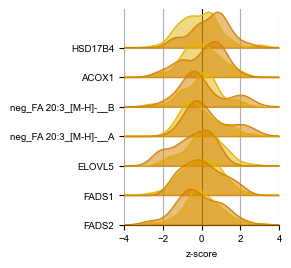

In [42]:
two_group_ridge(
    make_dz_df(features, pufamet, "White"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "pufamet_white_npm1+-.png"),
)

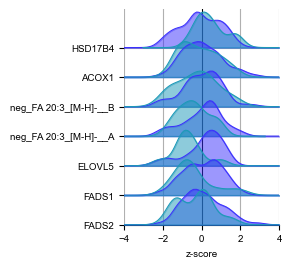

In [43]:
two_group_ridge(
    make_dz_df(features, pufamet, "Black"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "pufamet_black_npm1+-.png"),
)

In [46]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType").is_in(["Proteomics", "Lipidomics", "Metabolomics"]))
        & (pl.col("Feature").is_in([_[0] for _ in pufamet]))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""ELOVL5""",-0.829614,0.007459,0.675214,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""ELOVL5""",-0.537913,0.009941,0.999894,"""White_NPM1+/FLT3-ITD-_vs_White…"
"""HSD17B4""",0.491294,0.00879,0.999894,"""White_NPM1+/FLT3-ITD-_vs_White…"


In [ ]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType").is_in(["Proteomics", "Lipidomics", "Metabolomics"]))
        & (pl.col("Feature").is_in([_[0] for _ in pufamet]))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""HSD17B4""",-0.424584,0.001371,0.00473,"""Black_NPM1-/FLT3-ITD-_vs_White…"


## lipid remodeling

In [ ]:
remodeling = [
    # both 
    ("LPCAT3", "Proteomics"),
    # ω-6
    ("ACSL4", "Proteomics"),
    ("PLA2G4A", "Proteomics"),
    ("rpneg_Arachidonic.acid", "Metabolomics"),
    ("pos_PC 37:4|PC 17:0_20:4_[M+H]+", "Lipidomics"),
    ("pos_PC 38:5|PC 18:1_20:4_[M+H]+", "Lipidomics"),
    ("pos_PC 42:9|PC 20:4_22:5_[M+H]+", "Lipidomics"),
    ("neg_PE 36:5|PE 16:1_20:4_[M-H]-__A", "Lipidomics"),
    ("neg_PE 36:5|PE 16:1_20:4_[M-H]-__B", "Lipidomics"),
    ("neg_PE 37:4|PE 17:0_20:4_[M-H]-__A", "Lipidomics"),
    ("neg_PE 37:4|PE 17:0_20:4_[M-H]-__B", "Lipidomics"),
    ("neg_PE 38:5|PE 18:1_20:4_[M-H]-__A", "Lipidomics"),
    ("neg_PE 38:5|PE 18:1_20:4_[M-H]-__B", "Lipidomics"),
    ("pos_LPC 20:4/0:0_[M+H]+", "Lipidomics"),
    ("pos_LPC 20:4_[M+H]+", "Lipidomics"),
    ("neg_LPE 20:4_[M-H]-__B", "Lipidomics"),
    ("neg_LPE 20:4_[M-H]-__C", "Lipidomics"),
    # ignore ether/plasmalogen for now
    # ("pos_PC O-36:5|PC O-16:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-38:5|PC O-18:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-38:6|PC O-18:2_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-42:5|PC O-22:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-42:6|PC O-22:2_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-44:5|PC O-24:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-44:6|PC O-24:2_20:4_[M+H]+", "Lipidomics"),
    # ("neg_PE O-38:6|PE O-18:2_20:4_[M-H]-", "Lipidomics"),
    # ω-3
    #("ASL6", "Proteomics"),
    #("PLA2G6", "Proteomics"),
    ("pos_PC 40:7|PC 18:1_22:6_[M+H]+", "Lipidomics"),
    ("pos_LPC 22:6/0:0_[M+H]+", "Lipidomics"),
    ("pos_LPC 22:6_[M+H]+", "Lipidomics"),
    ("neg_LPE 22:6_[M-H]-__A", "Lipidomics"),
    ("neg_LPE 22:6_[M-H]-__B", "Lipidomics"),
    # ignore ether/plasmalogen for now
    # ("pos_PC O-40:7|PC O-18:1_22:6_[M+H]+__A", "Lipidomics"),
    # ("pos_PC O-40:7|PC O-18:1_22:6_[M+H]+__B", "Lipidomics"),
    # ("pos_PE P-40:7|PE P-18:1_22:6_[M+H]+__A", "Lipidomics"),
    # ("pos_PE P-40:7|PE P-18:1_22:6_[M+H]+__B", "Lipidomics"),
]

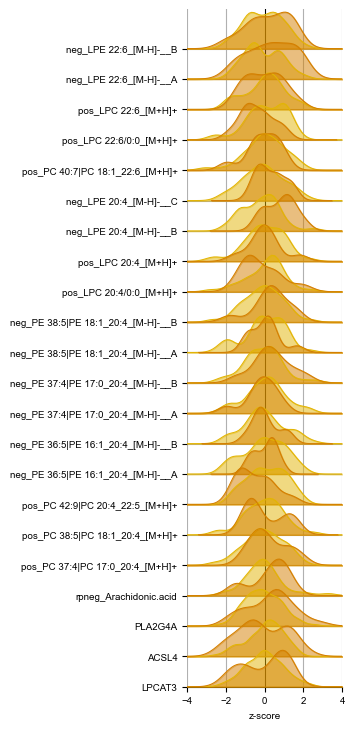

In [62]:
two_group_ridge(
    make_dz_df(features, remodeling, "White"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "remodeling_white_npm1+-.png"),
)

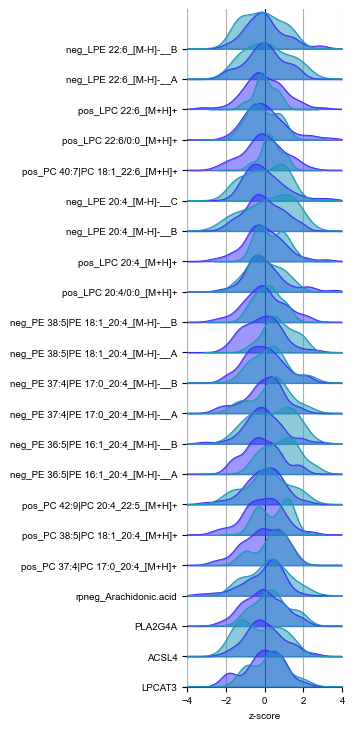

In [63]:
two_group_ridge(
    make_dz_df(features, remodeling, "Black"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "remodeling_black_npm1+-.png"),
)

In [64]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType").is_in(["Proteomics", "Lipidomics", "Metabolomics"]))
        & (pl.col("Feature").is_in([_[0] for _ in remodeling]))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""neg_PE 36:5|PE 16:1_20:4_[M-H]…",0.853678,0.010539,0.451863,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""neg_PE 38:5|PE 18:1_20:4_[M-H]…",0.608257,0.02142,0.489798,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""neg_LPE 20:4_[M-H]-__B""",0.640816,0.028037,0.722198,"""White_NPM1+/FLT3-ITD-_vs_White…"


In [65]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType").is_in(["Proteomics", "Lipidomics", "Metabolomics"]))
        & (pl.col("Feature").is_in([_[0] for _ in remodeling]))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""neg_PE 36:5|PE 16:1_20:4_[M-H]…",0.403734,0.021278,0.993146,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""neg_PE 38:5|PE 18:1_20:4_[M-H]…",0.339563,0.047591,0.993146,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""LPCAT3""",-0.391205,0.004969,0.013515,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""PLA2G4A""",-0.326144,0.028216,0.056918,"""Black_NPM1-/FLT3-ITD-_vs_White…"


In [ ]:
remodeling_groups_defs = {
    # both 
    "LPCAT3": [("LPCAT3", "Proteomics")],
    # ω-6
    "ACSL4": [("ACSL4", "Proteomics")],
    "PLA2G4A": [("PLA2G4A", "Proteomics")],
    "FA 20:4 (ARA)": [("rpneg_Arachidonic.acid", "Metabolomics")],
    "PC 20:4_X:X": [
        ("pos_PC 37:4|PC 17:0_20:4_[M+H]+", "Lipidomics"),
        ("pos_PC 38:5|PC 18:1_20:4_[M+H]+", "Lipidomics"),
        ("pos_PC 42:9|PC 20:4_22:5_[M+H]+", "Lipidomics"),
    ],
    "PE 20:4_X:X": [
        ("neg_PE 36:5|PE 16:1_20:4_[M-H]-__A", "Lipidomics"),
        ("neg_PE 36:5|PE 16:1_20:4_[M-H]-__B", "Lipidomics"),
        ("neg_PE 37:4|PE 17:0_20:4_[M-H]-__A", "Lipidomics"),
        ("neg_PE 37:4|PE 17:0_20:4_[M-H]-__B", "Lipidomics"),
        ("neg_PE 38:5|PE 18:1_20:4_[M-H]-__A", "Lipidomics"),
        ("neg_PE 38:5|PE 18:1_20:4_[M-H]-__B", "Lipidomics"),
    ],
    "LPC 20:4": [
        ("pos_LPC 20:4/0:0_[M+H]+", "Lipidomics"),
        ("pos_LPC 20:4_[M+H]+", "Lipidomics"),
    ],
    "LPE 20:4": [
        ("neg_LPE 20:4_[M-H]-__B", "Lipidomics"),
        ("neg_LPE 20:4_[M-H]-__C", "Lipidomics"),
    ],
    # ignore ether/plasmalogen for now
    # ("pos_PC O-36:5|PC O-16:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-38:5|PC O-18:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-38:6|PC O-18:2_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-42:5|PC O-22:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-42:6|PC O-22:2_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-44:5|PC O-24:1_20:4_[M+H]+", "Lipidomics"),
    # ("pos_PC O-44:6|PC O-24:2_20:4_[M+H]+", "Lipidomics"),
    # ("neg_PE O-38:6|PE O-18:2_20:4_[M-H]-", "Lipidomics"),
    # ω-3
    #("ASL6", "Proteomics"),
    #("PLA2G6", "Proteomics"),
    "PC 22:6_X:X": [("pos_PC 40:7|PC 18:1_22:6_[M+H]+", "Lipidomics")],
    "LPC 22:6_X:X": [
        ("pos_LPC 22:6/0:0_[M+H]+", "Lipidomics"),
        ("pos_LPC 22:6_[M+H]+", "Lipidomics"),
    ],
    "LPE 22:6_X:X": [
        ("neg_LPE 22:6_[M-H]-__A", "Lipidomics"),
        ("neg_LPE 22:6_[M-H]-__B", "Lipidomics"),
    ]
    # ignore ether/plasmalogen for now
    # ("pos_PC O-40:7|PC O-18:1_22:6_[M+H]+__A", "Lipidomics"),
    # ("pos_PC O-40:7|PC O-18:1_22:6_[M+H]+__B", "Lipidomics"),
    # ("pos_PE P-40:7|PE P-18:1_22:6_[M+H]+__A", "Lipidomics"),
    # ("pos_PE P-40:7|PE P-18:1_22:6_[M+H]+__B", "Lipidomics"),
}

In [70]:
# collect average expression for all of the gene sets into a data frame
# the expression levels of all individual gene set members are first 
# z-score normalized, then we take the mean across the gene set for each sample
# we do this separately for samples in both race groups
remodeling_groups = {
    race: pl.DataFrame(
        [
            [
                grp,
                (
                    features
                    .filter(
                        (pl.col("Race") == race)
                        & (pl.col("OmicsType").is_in(["Proteomics", "Metabolomics", "Lipidomics"]))
                        & (pl.col("Feature").is_in([_[0] for _ in remodeling_groups_defs[grp]]))
                        & ~pl.col("FLT3_ITD")
                    )
                    .group_by("Feature")
                    .agg(
                        "Signal",
                        "Sample",
                        "NPM1"
                    )
                    .with_columns(
                        pl.col("Signal").list.mean().alias("Signal_mean"),
                        pl.col("Signal").list.std().alias("Signal_std")
                    )
                    .with_columns(
                        ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                    )
                    .drop("Signal", "Signal_mean", "Signal_std")
                    .explode("Sample", "NPM1", "Z")
                    .filter(~pl.col("NPM1"))
                    .group_by("Sample")
                    .agg(pl.col("Z").mean())
                    ["Z"]
                    .to_list()
                ),
                (
                    features
                    .filter(
                        (pl.col("Race") == race)
                        & (pl.col("OmicsType").is_in(["Proteomics", "Metabolomics", "Lipidomics"]))
                        & (pl.col("Feature").is_in([_[0] for _ in remodeling_groups_defs[grp]]))
                        & ~pl.col("FLT3_ITD")
                    )
                    .group_by("Feature")
                    .agg(
                        "Signal",
                        "Sample",
                        "NPM1"
                    )
                    .with_columns(
                        pl.col("Signal").list.mean().alias("Signal_mean"),
                        pl.col("Signal").list.std().alias("Signal_std")
                    )
                    .with_columns(
                        ((pl.col("Signal") - pl.col("Signal_mean")) / pl.col("Signal_std")).alias("Z")
                    )
                    .drop("Signal", "Signal_mean", "Signal_std")
                    .explode("Sample", "NPM1", "Z")
                    .filter(pl.col("NPM1"))
                    .group_by("Sample")
                    .agg(pl.col("Z").mean())
                    ["Z"]
                    .to_list()
                ),
                
            ]
            for grp
            in remodeling_groups_defs.keys()
        ], schema=["feature", "A", "B"], orient="row").with_row_index()
    for race in ["Black", "White"]
}

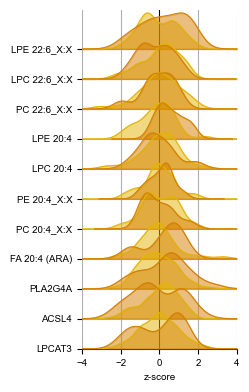

In [71]:
two_group_ridge(
    remodeling_groups["White"],
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "remodeling_groups_white_npm1+-.png"),
)

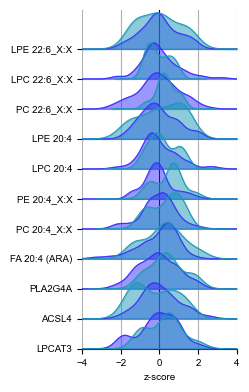

In [72]:
two_group_ridge(
    remodeling_groups["Black"],
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "remodeling_groups_black_npm1+-.png"),
)

## Activation

In [ ]:
activation = [
    # both 
    ("ALOX5", "Proteomics"),
    # ω-6
    ("ALOX15", "Proteomics"),
]

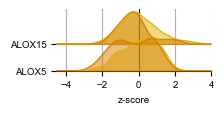

In [78]:
two_group_ridge(
    make_dz_df(features, activation, "White"),
    COLORS.WHITE_WT,
    COLORS.WHITE_NPM1,
    x_min=-4.5, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "activation_white_npm1+-.png"),
)

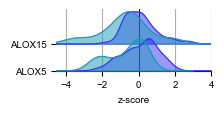

In [79]:
two_group_ridge(
    make_dz_df(features, activation, "Black"),
    COLORS.BLACK_WT,
    COLORS.BLACK_NPM1,
    x_min=-4.5, x_max=4,
    kde_height=1.2, kde_pad=1., bw_adjust=0.8, kde_points=100,
    fig_height_mult=0.4,
    fig_width=2.,
    xlabel="z-score",
    figname=os.path.join(FIGURE_DIR, "activation_black_npm1+-.png"),
)

In [76]:
# BvB, WvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_Black_NPM1-/FLT3-ITD-",
            "White_NPM1+/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-",
        ]))
        & (pl.col("OmicsType").is_in(["Proteomics", "Lipidomics", "Metabolomics"]))
        & (pl.col("Feature").is_in([_[0] for _ in activation]))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""ALOX15""",-1.328181,0.003591,0.510776,"""Black_NPM1+/FLT3-ITD-_vs_Black…"
"""ALOX5""",-0.828278,0.02061,0.959285,"""Black_NPM1+/FLT3-ITD-_vs_Black…"


In [77]:
# BvW
(
    limma
    .filter(
        (pl.col("Contrast").is_in([
            "Black_NPM1+/FLT3-ITD-_vs_White_NPM1+/FLT3-ITD-",
            "Black_NPM1-/FLT3-ITD-_vs_White_NPM1-/FLT3-ITD-"
        ]))
        & (pl.col("OmicsType").is_in(["Proteomics", "Lipidomics", "Metabolomics"]))
        & (pl.col("Feature").is_in([_[0] for _ in activation]))
        & (pl.col("P.Value") <= 0.05)
    )
    .select("Feature", "logFC", "P.Value", "adj.P.Val", "Contrast")
)

Feature,logFC,P.Value,adj.P.Val,Contrast
str,f64,f64,f64,str
"""ALOX15""",-0.527766,0.014608,0.033209,"""Black_NPM1-/FLT3-ITD-_vs_White…"
"""ALOX15""",-1.450731,0.00409,0.280145,"""Black_NPM1+/FLT3-ITD-_vs_White…"


## iScore

In [ ]:
iscore = [
    "IGLL1", "CD79B", "CD79A", "IGLC1", "PAX5", "IGHM", "IGKC", "HLA-DRA", 
    "CD81", "PSMB6", "HLA-DPB1", "IGLC2", "PSMB9", "SYK", "PSMB8", "PSMA6", 
    "IGHD", "PSMA4", "PSMA7", "HLA-DRB1", "CD38", "EZR", "CD44", "TYROBP", 
    "FTL", "LYZ", "ADGRE5", "PAFAH1B2", "MGST1", "CTSA", "CTSD", "RHOG", 
    "CFD", "ITGB2", "ATP6V0C", "PRAM1", "ATP8B4", "ADAM17", "TMEM30A", 
    "RNASET2", "KMT2E", "MANBA", "AZU1", "SDCBP", "GLIPR1", "CD63", "PTPRC", 
    "SLC2A3", "MPO", "CD36", "CTSG", "CXCL8", "UBC", "ANXA1", "NFKBIA", 
    "IL1RAP", "SQSTM1", "HIF1A", "CEBPB", "TFPI", "PELI1", "IRAK3", "PSME4", 
    "CCL5", "MAP3K8", "KLF2", "TRIB1", "ZFP36", "PTGER4", "PLCG2", "VIM", 
    "JUNB", "FOS", "RIOK3", "CTNNB1", "PIK3R1", "RGCC", "LRRFIP1", "STAT3", 
    "EIF2AK2", "DDIT3", "DDX21", "RUNX1", "HGF", "HIPK1", "CYLD", "ELF1", 
    "ADAR", "PARP14", "SOCS3", "IFI6", "IFI44L", "DDIT4", "IFITM2", "ISG15", 
    "CALCOCO2", "RBPJ", "MX1", "LYST", "HOXA9", "VSIR", "ID2", "ATP2B1", "HOMER3", 
    "SRGN", "B2M", "CST3", "COTL1", "FCER1G", "FCN1", "FGL2", "CTSS", "MNDA", "CYBA", 
    "S100A11", "ARPC5", "S100A9", "SLC11A1", "CLEC12A", "GSTP1", "CD14", "S100A12", 
    "CPPED1", "SERPINA1", "GCA", "CTSZ", "PYCARD", "TNFRSF1B", "S100A8", "LILRB2", 
    "LAMTOR1", "PECAM1", "CAP1", "NPC2", "CTSH", "C5AR1", "GDI2", "TRAPPC1", "DBNL", 
    "RETN", "VAMP8", "LTA4H", "SELL", "HSPA1A", "DYNLL1", "ALOX5", "IQGAP2", "FGR", 
    "FPR1", "CDA", "LILRB3", "CD74", "AP2S1", "HLA-DPA1", "NCF2", "CLEC4A", 
    "HLA-DQB1", "HLA-DMB", "HLA-DMA", "PSME1", "PSME2", "HLA-DQA1", "HLA-E", 
    "HLA-DRB5", "CAPZB", "HLA-F", "NCF1", "ACTB", "ARPC3", "FCGR3A", "ARPC1B", 
    "FYB1", "BRK1", "ICAM3", "HCK", "FYN", "ARPC4", "MEF2C", "LILRB1", "THEMIS2", 
    "FCER1A", "CD48", "POU2F2", "CD86", "TNFSF13B", "TNFSF13", "IRF1", "AIF1", "CSF1R", 
    "LRRK2", "SULF2", "CASP1", "PARK7", "LILRA5", "GPSM3", "CYP1B1", "CNPY3", "CD300LF", 
    "ARRB2", "IRF2", "SAMHD1", "TSPO", "CX3CR1", "LST1", "DUSP1", "TMEM176B", "RIPOR2", 
    "TMEM176A", "CLU", "CDK6", "IFI27", "HMGA1", "RNASE2", "TRIM11", "CXCR4", "TNFAIP3", 
    "OASL", "IFNGR1", "PMAIP1", "IFIT3", "THBD", "MAPKAPK2", "CXCL3", "CXCL2", "ELANE", 
    "ADM", "CCL3", "LITAF", "IL1RN", "HMOX1", "PRNP", "CD84", "BCL6", "RABGEF1", "CD83", 
    "MYB", "ATF4", "ARHGEF2", "HSPA5", "PPP1R15B", "PABPC1", "P4HB", "CHMP4B", "MAFB", 
    "CCL7", "CCL3L1"
]